# **Bin Packing v4 — 영상 단위 적재 · 같은 상자를 모두 싣고 차지한 부피로 비교 (val로 여유 선택 → test 한 번)**

> 메인 노트북 [X-1]이 저장한 `outputs/binpack/{split}_binpack_input.csv`(최종 치수 `prop`, 오프라인)와 ablation [H-3]의 LIFT A-1R 치수만 읽는다. 치수 모델은 다시 돌리지 않는다. 결과 파일은 `binpack4_*`.

## 질문
1. 상자 치수를 미리 알고 순서 · 자리를 계획하면, **들어온 순서대로 쌓는 현행(하한)보다 같은 상자를 더 작은 공간에** 실을 수 있나?
2. 기존 방법(LIFT A-1R) 치수보다 제안 치수의 효과가 큰가?
3. 정답 치수로 계획한 **상한**에 얼마나 가까운가? 차이는 **검출 손실**(미검출 · 정답 없는 트랙)과 **치수 손실** 중 어디서 오나?

## 설정
- **영상 하나 = 적재 작업 하나.** 순서 바꾸기 · 계획은 영상 안에서만
- **모든 실제 상자(매칭 + 미검출)를 반드시 싣는다.** 받침 75%, 6방향 회전
- **지표:** 적재 밀도 % = 실제 상자 부피 합 ÷ 적재 공간(놓인 상자를 감싸는 직육면체) 부피 · 공간 부피(L) · 재배치 %(계획 자리에 실제 상자가 안 맞아 다시 놓은 비율 = 현장 재작업)
- **적재 규칙 (모든 행 같음, [P-1]):** 폭 W · 높이 H를 정한 칸에 벽을 쌓듯이 — 상자가 오면 가능한 모든 자리 × 방향 중 **길이가 가장 덜 늘어나는 자리**. 칸은 후보(W 60 · 90 · 120, H 60 · 100 · 140 cm) 중 **공간 부피가 가장 작은 배치** (하한도 같은 후보 중 최선 → 보수적 비교). 방법 행은 추정 치수로 계획한 배치로 칸을 정함

| 행 | 계획 치수 | 순서 | 의미 |
| --- | --- | --- | --- |
| **하한 (현행)** | 정답 (작업자가 상자를 보고 놓음) | **들어온 순서** (그 안에서 상자마다 가장 좋은 자리) | 지금 현장. 앞으로 올 상자를 모르므로 칸은 **val에서 고른 표준 칸 하나** |
| 하한 (칸 사후 최선) | 정답 | 들어온 순서 | 참고: 칸을 영상마다 사후 최선으로 (하한에 가장 유리한 보수적 비교) |
| LIFT A-1R · (순서 계획 / 자리 고정) | 추정 + 여유 | 큰 상자부터 | 기존 방법 (현장 미세조정 + 레일 보정) |
| **제안 (최종) · (순서 계획 / 자리 고정)** | 추정 + 여유 | 큰 상자부터 | 우리 방법 |
| 우리 검출 + 정답 치수 | 매칭 상자는 정답, 정답 없는 트랙은 제안 치수 | 큰 상자부터 | 검출 손실 · 치수 손실 분리 |
| **상한** | 정답 · 모든 실제 상자 | 큰 상자부터 | 완벽한 검출 + 치수 |

- **방법 행의 실제 적재 (두 방식):** 추정 치수로 순서(큰 것부터) · 칸을 계획한 뒤
  - **순서 계획 (주 결과):** 실제 상자가 그 순서로 오고, 작업자가 상자를 보며 가장 좋은 자리에 놓음 → 치수를 미리 아는 가치 = 순서를 계획할 수 있음
  - **자리 고정 (엄격):** 계획한 자리 · 방향에 그대로 놓고, 안 맞으면 마지막에 남은 공간에 다시 놓음(재배치). 정답 없는 트랙의 자리는 빈 공간
  - 두 방식 모두 **미검출 상자는 마지막에 남은 공간에**
- **손실 분해:** 상한 − (우리 검출 + 정답 치수) = 검출 손실 · (우리 검출 + 정답 치수) − 제안 = 치수 손실
- **평가 순서:** A. val에서 방법마다 여유 9가지 중 밀도 평균 최대를 고름 → T. test 한 번 (그 여유 그대로)
- CPU 런타임으로 충분 (영상 하나 1초 안팎). 결과는 영상마다 바로 저장되어 끊겨도 이어서 실행


# **0. 준비 · 설정 · 적재 규칙**

In [1]:
# [B-0] Drive 연결 + 경로 + 한글 폰트 (외부 적재 라이브러리 없음 — 적재 규칙은 [P-1]에 직접 작성)
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess, json, time, math, glob, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT     = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT  = f'{ROOT}/BoxSizing'
DATA_DIR = f'{ROOT}/Dataset/Final Dataset'
EXP_DIR  = f'{PROJECT}/outputs/binpack'                  # 메인 [X-1] 입력 ({split}_binpack_input.csv) + 이 노트북 결과 (binpack4_*)
EXTRA_DIR = f'{EXP_DIR}/extra'                           # ablation [H-3]: {split}_lift_ft_A1R.csv
MAP_COL  = 'new_tracked_unique_id_VERSION5'
try:
    import matplotlib.font_manager as fm
    FP = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(FP):
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], check=False)
    fm.fontManager.addfont(FP); plt.rcParams['font.family'] = fm.FontProperties(fname=FP).get_name()
    plt.rcParams['axes.unicode_minus'] = False
except Exception as e:
    print('⚠️ 한글 폰트 없음:', type(e).__name__)
print('입력:', sorted(os.path.basename(p) for p in glob.glob(f'{EXP_DIR}/*_binpack_input.csv')),
      '· A-1R:', sorted(os.path.basename(p) for p in glob.glob(f'{EXTRA_DIR}/*_lift_ft_A1R.csv')))


Mounted at /content/drive
입력: ['test_binpack_input.csv', 'train_binpack_input.csv', 'val_binpack_input.csv'] · A-1R: ['test_lift_ft_A1R.csv', 'train_lift_ft_A1R.csv', 'val_lift_ft_A1R.csv']


In [2]:
# [B-1] 설정
SUPPORT, ROT6 = 0.75, True                         # 받침 75% · 6방향 회전
GRID_W, GRID_H = (60, 90, 120), (60, 100, 140)     # 칸 후보: 폭 · 쌓는 높이 (cm, 높이는 트럭 내부 239 cm 이하) → 공간 부피가 가장 작은 칸
MARGINS = [('없음', 'fixed', 0.0), ('+2 cm', 'fixed', 2.0), ('+3 cm', 'fixed', 3.0), ('+4 cm', 'fixed', 4.0),
           ('+5 cm', 'fixed', 5.0), ('+6 cm', 'fixed', 6.0), ('+10%', 'ratio', 0.10), ('+15%', 'ratio', 0.15),
           ('+20%', 'ratio', 0.20)]
MARGIN_BY_NAME = {m[0]: m for m in MARGINS}
METHOD_NAMES = {'lift_ft_A1R': 'LIFT A-1R', 'prop': '제안 (최종)'}   # 입력 열 앞부분 → 표 이름 (LIFT 원본도 보려면 'lift_raw': 'LIFT 원본' 추가)
REF = '제안 (최종) · 순서 계획'                         # 주 결과 = 순서 계획 (자리 고정은 엄격 검증)
EXPECT = {'val': (6, 6), 'test': (7, 8)}           # (미검출, 정답 없는 트랙) — 치수 지표 ③과 같아야 함
RUN_A, RUN_T = True, True                           # A = val로 여유 선택 · T = test 한 번
#  그림만 다시 그릴 때: 둘 다 False → 저장된 csv를 불러옴 (다시 계산 · test 재채점 없음)
res_path = lambda run, sp: f'{EXP_DIR}/binpack4_{run}_{sp}.csv'
BEST_PATH, TEST_MARK = f'{EXP_DIR}/binpack4_best_margin_val.json', f'{EXP_DIR}/binpack4_TEST_DONE.txt'
json.dump({'GRID_W': GRID_W, 'GRID_H': GRID_H, 'SUPPORT': SUPPORT, 'ROT6': ROT6, 'MARGINS': MARGINS, 'METHOD_NAMES': METHOD_NAMES},
          open(f'{EXP_DIR}/binpack4_settings.json', 'w'), ensure_ascii=False, indent=1)


In [3]:
# [P-1] 적재 휴리스틱 — 폭 W · 높이 H를 정한 칸에 벽을 쌓듯이 (모든 행에 같은 규칙)
#  - 좌표: x = 길이 (제한 없음) · y = 폭 (0 ~ W) · z = 높이 (0 ~ H, 중력은 -z). 적재 공간 = 놓인 상자를 감싸는 직육면체
#  - 상자가 오면: 후보 자리(extreme point) × 놓는 방향마다 들어가는지 확인 (폭 · 높이 안, 다른 상자와 겹침 없음,
#    바닥이 아니면 밑면의 SUPPORT 이상이 아래 상자 윗면에 받쳐짐) → 길이가 가장 덜 늘어나는 자리 (다음: 낮은 곳 · 안쪽)
#  - W · H는 후보 GRID_W × GRID_H 중 공간 부피가 가장 작은 배치를 고름 (pack_best). 탐욕 규칙이 탑처럼 쌓는 것을 막음
#  - 순서만 다르게 주면: 들어온 순서 = 하한(현행), 큰 상자부터 = 최적화
import itertools
EPS = 1e-6


def orientations(s):
    """세 변 (a, b, c) → 놓는 방향 목록 (중복 제거). ROT6이면 6방향, 아니면 높이 고정 2방향"""
    s = tuple(float(v) for v in s)
    perms = itertools.permutations(range(3)) if ROT6 else [(0, 1, 2), (1, 0, 2)]
    return list(dict.fromkeys(tuple(s[k] for k in p) for p in perms))


class Load:
    def __init__(self, W, H):
        self.W, self.H = float(W), float(H)
        self.lo, self.sz, self.eps = [], [], {(0.0, 0.0, 0.0)}

    def extent(self):
        return tuple(max((l[k] + s[k] for l, s in zip(self.lo, self.sz)), default=0.0) for k in range(3))

    def volume(self):
        X, Y, Z = self.extent(); return X * Y * Z

    def _overlap(self, p, d):
        for l, s in zip(self.lo, self.sz):
            if (p[0] < l[0] + s[0] - EPS and l[0] < p[0] + d[0] - EPS and p[1] < l[1] + s[1] - EPS and l[1] < p[1] + d[1] - EPS
                    and p[2] < l[2] + s[2] - EPS and l[2] < p[2] + d[2] - EPS):
                return True
        return False

    def _support(self, p, d):
        if p[2] <= EPS: return 1.0
        area = 0.0
        for l, s in zip(self.lo, self.sz):
            if abs(l[2] + s[2] - p[2]) > 1e-3: continue
            ox = min(p[0] + d[0], l[0] + s[0]) - max(p[0], l[0]); oy = min(p[1] + d[1], l[1] + s[1]) - max(p[1], l[1])
            if ox > 0 and oy > 0: area += ox * oy
        return area / (d[0] * d[1])

    def fits(self, p, d):
        return (p[1] + d[1] <= self.W + EPS and p[2] + d[2] <= self.H + EPS and min(p) >= -EPS
                and not self._overlap(p, d) and self._support(p, d) >= SUPPORT - 1e-9)

    def _project(self, q, ax):
        """점 q를 ax 축 음의 방향으로 밀어 처음 닿는 면 (또는 0)"""
        best = 0.0; o = [k for k in range(3) if k != ax]
        for l, s in zip(self.lo, self.sz):
            if all(l[k] - EPS <= q[k] < l[k] + s[k] - EPS for k in o) and l[ax] + s[ax] <= q[ax] + EPS:
                best = max(best, l[ax] + s[ax])
        r = list(q); r[ax] = best
        return tuple(r)

    def best_spot(self, s):
        L0, best = self.extent()[0], None
        for p in self.eps:
            for d in orientations(s):
                if not self.fits(p, d): continue
                key = (round(max(L0, p[0] + d[0]), 3), round(p[2], 3), round(p[0], 3), round(p[1], 3))   # 길이 → 높이 → 안쪽 → 왼쪽
                if best is None or key < best[0]: best = (key, p, d)
        return best

    def put(self, p, d):
        self.lo.append(tuple(p)); self.sz.append(tuple(d))
        x, y, z = p; dx, dy, dz = d
        for q in ((x + dx, y, z), (x, y + dy, z), (x, y, z + dz)):
            self.eps.add(q)
            for ax in range(3): self.eps.add(self._project(q, ax))
        self.eps = {q for q in self.eps if q[1] < self.W - EPS and q[2] < self.H - EPS}

    def place(self, s):
        b = self.best_spot(s)
        if b is None:                                                     # 길이는 제한이 없으므로 맨 뒤 바닥에는 들어감
            ok = [d for d in orientations(s) if d[1] <= self.W + EPS and d[2] <= self.H + EPS]
            if not ok: raise ValueError('칸보다 큰 상자')
            d = min(ok, key=lambda d: d[0]); p = (self.extent()[0], 0.0, 0.0); b = (None, p, d)
        self.put(b[1], b[2]); return b[1], b[2]


def pack(sizes, order, W, H):
    """sizes: (n, 3), order: 놓는 순서 → Load + 상자마다 (위치, 놓인 방향의 치수)"""
    ld, pl = Load(W, H), {}
    for i in order: pl[i] = ld.place(sizes[i])
    return ld, pl


def pack_best(sizes, order):
    """칸 후보마다 쌓아 보고 공간 부피가 가장 작은 배치 → (Load, 배치, (W, H))"""
    best = None
    for W in GRID_W:
        for H in GRID_H:
            try: ld, pl = pack(sizes, order, W, H)
            except ValueError: continue                                   # 칸보다 큰 상자가 있으면 그 칸은 제외
            if best is None or ld.volume() < best[0].volume() - 1e-9: best = (ld, pl, (W, H))
    return best


# **1. 입력 · 평가 함수**

In [4]:
# [B-2] 입력 — 영상마다: 매칭 쌍 + 정답 없는 트랙 (시스템이 본 상자) + 미검출 상자 (실제로만 옴)
#  - 메인 [X-1]의 {split}_binpack_input.csv (세 변 큰 순) + A-1R 열이 없으면 extra/{split}_lift_ft_A1R.csv를 붙임
#  - 미검출 상자의 도착 프레임은 box_id 순서에서 앞뒤 매칭 상자의 프레임 사이 값으로 추정
def sort3(a):
    return -np.sort(-np.asarray(a, float), axis=-1)


def load_labels(path):
    out = {}
    for v in json.load(open(path))['videos']:
        objs = sorted(v['objects'], key=lambda o: o['box_id'])
        out[v['video_id']] = [{'box_id': int(o['box_id']), 'w': float(o['size_cm']['w']), 'd': float(o['size_cm']['d']),
                               'h': float(o['size_cm']['h'])} for o in objs]
    return out


def load_mapping(path):
    m = pd.read_excel(path); out = {}
    for vid, g in m.groupby('video_id'):
        rows = []
        for _, r in g.sort_values('box_id_json').iterrows():
            try: trk = int(float(r[MAP_COL]))
            except (TypeError, ValueError): trk = None
            rows.append({'box_id': int(r['box_id_json']), 'trk': trk, 'removed': str(r.get('note', '')).strip().upper() == 'REMOVED'})
        out[str(vid)] = rows
    return out


def build(sp):
    T = pd.read_csv(f'{EXP_DIR}/{sp}_binpack_input.csv')
    for nm in [k for k in METHOD_NAMES if f'{k}_1' not in T.columns]:
        p = f'{EXTRA_DIR}/{sp}_{nm}.csv'; assert os.path.exists(p), f'{nm} 치수 없음: {p}'
        e = pd.read_csv(p); s = sort3(e[['w', 'd', 'h']].values)
        T = T.merge(e[['vid', 'tid']].assign(**{f'{nm}_{j + 1}': s[:, j] for j in range(3)}), on=['vid', 'tid'], how='left')
    for k in METHOD_NAMES:
        cols = [f'{k}_{j}' for j in (1, 2, 3)]; miss = T[cols].isna().any(axis=1)
        if miss.any():
            T.loc[miss, cols] = T.loc[~miss, cols].median().values; print(f'  ⚠️ {sp} {METHOD_NAMES[k]}: 치수 없는 트랙 {int(miss.sum())}개 → 중앙값')
    labels, maps = load_labels(f'{DATA_DIR}/{sp}_label.json'), load_mapping(f'{PROJECT}/{sp}_label_mapping.xlsx')
    trk = set(zip(T.vid, T.tid.astype(int))); ff = dict(zip(zip(T.vid, T.tid.astype(int)), T.first_frame)); rows = []
    for vid in sorted(labels):
        mp = maps.get(vid, []); removed = {m['box_id'] for m in mp if m['removed']}
        link = {m['box_id']: m['trk'] for m in mp if not m['removed'] and m['trk'] is not None}
        boxes = [g for g in labels[vid] if g['box_id'] not in removed]
        known = {g['box_id']: ff[(vid, link[g['box_id']])] for g in boxes if link.get(g['box_id']) is not None and (vid, link[g['box_id']]) in trk}
        order = [g['box_id'] for g in boxes]
        for k, g in enumerate(boxes):
            if g['box_id'] in known: continue
            prev = [known[b] for b in order[:k] if b in known]; nxt = [known[b] for b in order[k + 1:] if b in known]
            f = (prev[-1] + nxt[0]) / 2 if prev and nxt else (prev[-1] + 15 if prev else (max(nxt[0] - 15, 0) if nxt else 30 * k))
            gs = sort3([g['w'], g['d'], g['h']])
            rows.append({'vid': vid, 'tid': -1, 'box_id': g['box_id'], 'kind': 'missed', 'first_frame': f, 'gt_1': gs[0], 'gt_2': gs[1], 'gt_3': gs[2]})
    T['kind'] = np.where(T.mapped, 'matched', 'fp')
    keep = ['vid', 'tid', 'box_id', 'kind', 'first_frame', 'gt_1', 'gt_2', 'gt_3'] + [f'{k}_{j}' for k in METHOD_NAMES for j in (1, 2, 3)]
    D = pd.concat([T[keep], pd.DataFrame(rows)], ignore_index=True).sort_values(['vid', 'first_frame']).reset_index(drop=True)
    cnt = D.kind.value_counts().to_dict(); ok = (cnt.get('missed', 0), cnt.get('fp', 0)) == EXPECT.get(sp, (None, None))
    print(f"{sp}: 영상 {D.vid.nunique()} · 매칭 {cnt.get('matched', 0)} · 미검출 {cnt.get('missed', 0)} · 정답 없는 트랙 {cnt.get('fp', 0)} "
          + ('✅ 지표 ③과 일치' if ok else f'⚠️ 기대 {EXPECT.get(sp)}와 다름'))
    return D


D4 = {sp: build(sp) for sp in ['val'] + (['test'] if RUN_T else [])}


val: 영상 49 · 매칭 461 · 미검출 6 · 정답 없는 트랙 6 ✅ 지표 ③과 일치
test: 영상 50 · 매칭 469 · 미검출 7 · 정답 없는 트랙 8 ✅ 지표 ③과 일치


In [5]:
# [B-3] 영상 하나 평가 — 모든 실제 상자(매칭 + 미검출)를 반드시 싣고, 차지한 공간 부피 · 밀도 비교
#  칸(폭 W · 높이 H): 치수를 미리 아는 행은 영상마다 계획으로 정함 (후보 중 공간 부피가 가장 작은 배치, [P-1] pack_best)
#  하한 (현행)          : 실제 상자를 정답 치수로, 들어온 순서대로 (그 순서 안에서 상자마다 가장 좋은 자리)
#                         앞으로 올 상자를 모르므로 칸은 고정 — 칸 후보마다 계산해 두고 val 평균이 가장 좋은 칸 하나를 현장 표준으로 ([B-5])
#  하한 (칸 사후 최선)   : 참고 — 칸을 영상마다 사후에 최선으로 (하한에 가장 유리한 보수적 비교)
#  상한                 : 실제 상자를 정답 치수로, 큰 상자부터 (치수를 모두 미리 알고 순서를 바꿈)
#  방법 (LIFT · 제안)   : 시스템이 본 상자(매칭 + 정답 없는 트랙)를 추정 치수(+ 여유)로 큰 것부터 계획 → 실제 적재는 두 방식
#      순서 계획 (주 결과) : 추정 치수로 정한 순서 · 칸대로 실제 상자가 오고, 작업자가 상자를 보며 가장 좋은 자리에 놓음
#      자리 고정 (엄격)    : 실제 상자를 계획한 자리 · 방향에 그대로 (안 맞으면 마지막에 남은 공간에 다시 놓음 = 재배치)
#                            정답 없는 트랙의 계획 자리는 아무것도 안 와서 빈 공간
#      두 방식 모두 미검출 상자는 마지막에 남은 공간에
#  우리 검출 + 정답 치수 : 방법과 같지만 매칭 상자는 정답 치수로 계획 (정답 없는 트랙은 제안 치수) → 검출 손실 · 치수 손실 분리
#  밀도 % = 실제 상자 부피 합 ÷ 적재 공간(놓인 상자를 감싸는 직육면체) 부피 × 100
GT = ['gt_1', 'gt_2', 'gt_3']


def inflate(s, kind, m):
    s = np.asarray(s, float); return s + m if kind == 'fixed' else s * (1 + m)


def axis_perm(sorted_plan, d_plan):
    """계획 방향의 각 축이 계획 치수(큰 순)의 몇 번째 변인가 → 실제 상자도 같은 순위의 변을 그 축으로"""
    left, perm = list(range(3)), []
    for v in d_plan:
        k = min(left, key=lambda j: abs(sorted_plan[j] - v)); perm.append(k); left.remove(k)
    return perm


def metrics(ld, vol_real, n_rework=0, n_plan=0):
    X, Y, Z = ld.extent(); V = X * Y * Z
    return {'밀도 %': 100 * vol_real / V, '공간 L': V / 1e3, '길이 cm': X, '폭 cm': Y, '높이 cm': Z, '재배치': n_rework,
            '재배치 %': 100 * n_rework / max(n_plan, 1)}


MODES = ('순서 계획', '자리 고정')


def plan_and_load(seen_plan, seen_gt, is_fp, missed_gt, mode='순서 계획'):
    """seen_plan: 계획 치수 (큰 순), seen_gt: 실제 치수 (큰 순, 정답 없는 트랙은 무시) → 실제 적재 Load · 재배치 수"""
    order = list(np.argsort(-seen_plan.prod(1), kind='stable'))
    _, plan, (W, H) = pack_best(seen_plan, order)                         # 계획 (추정 치수로 순서 · 칸까지 정함)
    ld, rework, n_real = Load(W, H), [], 0
    if mode == '순서 계획':
        for i in order:
            if not is_fp[i]: n_real += 1; ld.place(seen_gt[i])            # 작업자가 실제 상자를 보며 가장 좋은 자리에
        for s in missed_gt: ld.place(s)
        return ld, 0, n_real
    for i in order:                                                       # 실제 상자가 계획 순서대로 도착 → 계획 자리에
        if is_fp[i]: continue
        n_real += 1; p, d_plan = plan[i]
        d_true = tuple(seen_gt[i][k] for k in axis_perm(seen_plan[i], d_plan))
        if ld.fits(p, d_true): ld.put(p, d_true)
        else: rework.append(i)
    for i in rework: ld.place(seen_gt[i])                                 # 안 맞은 상자 → 남은 공간에 다시
    for s in missed_gt: ld.place(s)                                       # 미검출 상자 → 마지막에 남은 공간에
    return ld, len(rework), n_real


def evaluate_video(df, margins):
    real = df[df.kind != 'fp']; seen = df[df.kind != 'missed'].reset_index(drop=True)
    g_real = real[GT].values; vol = float(g_real.prod(1).sum())
    is_fp = (seen.kind == 'fp').values; g_seen = seen[GT].values; missed = df.loc[df.kind == 'missed', GT].values
    base = {'실제 상자': len(real), '미검출': len(missed), '정답 없는 트랙': int(is_fp.sum())}
    rows = []
    best_low = None
    for W in GRID_W:                                                      # real은 first_frame 순 → 들어온 순서
        for H in GRID_H:
            try: ld, _ = pack(g_real, list(range(len(g_real))), W, H)
            except ValueError: continue
            rows.append({'행': '하한 (현행: 들어온 순서)', '여유': f'칸 {W}×{H}', **base, **metrics(ld, vol)})
            if best_low is None or ld.volume() < best_low.volume(): best_low = ld
    rows.append({'행': '하한 (칸 사후 최선)', '여유': '-', **base, **metrics(best_low, vol)})
    ld, _, _ = pack_best(g_real, list(np.argsort(-g_real.prod(1), kind='stable')))
    rows.append({'행': '상한 (정답 치수 · 큰 것부터)', '여유': '-', **base, **metrics(ld, vol)})
    plan_gt = np.where(is_fp[:, None], seen[[f'prop_{j}' for j in (1, 2, 3)]].values, g_seen)
    for mode in MODES:
        ld, nr, npl = plan_and_load(plan_gt, g_seen, is_fp, missed, mode)
        rows.append({'행': f'우리 검출 + 정답 치수 · {mode}', '여유': '-', **base, **metrics(ld, vol, nr, npl)})
    for key, name in METHOD_NAMES.items():
        est = seen[[f'{key}_{j}' for j in (1, 2, 3)]].values
        for mode in MODES:
            for mname in margins.get(f'{name} · {mode}', []):
                _, kind, m = MARGIN_BY_NAME[mname]
                ld, nr, npl = plan_and_load(sort3(inflate(est, kind, m)), g_seen, is_fp, missed, mode)
                rows.append({'행': f'{name} · {mode}', '여유': mname, **base, **metrics(ld, vol, nr, npl)})
    return rows


def run(run_id, sp, margins):
    path = res_path(run_id, sp); done = set(pd.read_csv(path).vid) if os.path.exists(path) else set(); t0 = time.time()
    for vid, g in D4[sp].groupby('vid', sort=True):
        if vid in done: continue
        R = pd.DataFrame(evaluate_video(g.sort_values('first_frame'), margins)); R.insert(0, 'vid', vid)
        R.to_csv(path, mode='a', header=not os.path.exists(path), index=False)
    R = pd.read_csv(path); R['여유'] = R['여유'].astype(str)
    print(f'✅ {run_id} {sp}: 영상 {R.vid.nunique()}개 · {time.time() - t0:.0f}s → {os.path.basename(path)}')
    return R


In [6]:
# [B-4] 요약 도구 — 영상 단위 bootstrap 95% CI · 같은 영상끼리 짝지은 비교
B_RNG = np.random.default_rng(0)
METHOD_ROWS = [f'{n} · {m}' for m in ('순서 계획', '자리 고정') for n in METHOD_NAMES.values()]
LOW = '하한 (현행: 들어온 순서)'
ROW_ORDER = ([LOW, '하한 (칸 사후 최선)'] + [r for r in METHOD_ROWS if r.endswith('순서 계획')] + ['우리 검출 + 정답 치수 · 순서 계획']
             + [r for r in METHOD_ROWS if r.endswith('자리 고정')] + ['우리 검출 + 정답 치수 · 자리 고정', '상한 (정답 치수 · 큰 것부터)'])


def boot_ci(x, n=2000):
    x = np.asarray(x, float)
    if len(x) < 2: return np.nan, np.nan
    m = [x[B_RNG.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return np.percentile(m, 2.5), np.percentile(m, 97.5)


def fmt(x):
    lo, hi = boot_ci(x); return f'{np.mean(x):.1f} [{lo:.1f}, {hi:.1f}]'


def pick(R, row, mg):
    return R[(R['행'] == row) & (R['여유'] == mg)].set_index('vid')


def chosen(R, best):
    """행마다 쓸 여유: 방법은 val에서 고른 여유, 나머지는 '-'"""
    return [(row, best.get(row, '-')) for row in ROW_ORDER if ((R['행'] == row) & (R['여유'] == best.get(row, '-'))).any()]


def report(R, best):
    out = []
    for row, mg in chosen(R, best):
        s = pick(R, row, mg)
        out.append({'행': row, '여유': mg, '밀도 %': fmt(s['밀도 %']), '공간 L': fmt(s['공간 L']), '높이 cm': f"{s['높이 cm'].mean():.0f}",
                    '재배치 %': fmt(s['재배치 %']) if row.endswith('자리 고정') else '—'})
    return pd.DataFrame(out).set_index(['행', '여유'])


def paired(R, best, col='밀도 %', ref=REF):
    P = pick(R, ref, best[ref])[col]; rows = []; mode = ref.rsplit(' · ', 1)[1]
    for row, mg in chosen(R, best):
        if row == ref or ((row in METHOD_ROWS or row.startswith('우리')) and not row.endswith(mode)): continue
        d = (P - pick(R, row, mg)[col]).dropna(); lo, hi = boot_ci(d)
        rows.append({'비교': f'{ref} − {row} ({mg})', f'{col} 차이': f'{d.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]', '영상': len(d)})
    # 손실 분해: 상한 − 우리 검출 + 정답 치수 = 검출 손실 · 우리 검출 + 정답 치수 − 제안 = 치수 손실 (같은 적재 방식)
    U, Gd = pick(R, ROW_ORDER[-1], '-')[col], pick(R, f'우리 검출 + 정답 치수 · {mode}', '-')[col]
    for name, d in ((f'검출 손실 (상한 − 우리 검출 + 정답 치수 · {mode})', U - Gd), (f'치수 손실 (우리 검출 + 정답 치수 − 제안 · {mode})', Gd - P)):
        lo, hi = boot_ci(d.dropna()); rows.append({'비교': name, f'{col} 차이': f'{d.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]', '영상': int(d.notna().sum())})
    return pd.DataFrame(rows).set_index('비교')


# **2. 실험 A — val로 여유 선택**

In [7]:
# [B-5] 실험 A — val: 방법마다 여유 9가지 → 밀도 평균이 가장 높은 여유 선택 (test는 이 여유 그대로)
RES_A = run('A', 'val', {r: [m[0] for m in MARGINS] for r in METHOD_ROWS}) if RUN_A else pd.read_csv(res_path('A', 'val'))
RES_A['여유'] = RES_A['여유'].astype(str)
BEST = {r: str(RES_A[RES_A['행'] == r].groupby('여유')['밀도 %'].mean().idxmax()) for r in METHOD_ROWS + [LOW]}   # 하한은 고정 칸 하나
json.dump(BEST, open(BEST_PATH, 'w'), ensure_ascii=False, indent=1); print('val에서 고른 여유 · 하한의 표준 칸:', BEST)
print('■ 하한 — 칸별 밀도 % (val 평균, 들어온 순서)')
display(RES_A[RES_A['행'] == LOW].groupby('여유')['밀도 %'].mean().sort_values(ascending=False).round(2).to_frame())
print('■ 여유별 밀도 % (val, 평균)')
display(RES_A[RES_A['행'].isin(METHOD_ROWS)].pivot_table(index='여유', columns='행', values='밀도 %', aggfunc='mean')
        .reindex([m[0] for m in MARGINS]).round(2))
print('■ val 결과 (평균 [95% CI])'); display(report(RES_A, BEST))
print('■ val 짝지은 비교 · 손실 분해 (밀도 %p) — 순서 계획 (주 결과)'); display(paired(RES_A, BEST))
print('■ val 짝지은 비교 · 손실 분해 (밀도 %p) — 자리 고정 (엄격)'); display(paired(RES_A, BEST, ref=REF.replace('순서 계획', '자리 고정')))


✅ A val: 영상 49개 · 0s → binpack4_A_val.csv
val에서 고른 여유 · 하한의 표준 칸: {'LIFT A-1R · 순서 계획': '없음', '제안 (최종) · 순서 계획': '+10%', 'LIFT A-1R · 자리 고정': '없음', '제안 (최종) · 자리 고정': '없음', '하한 (현행: 들어온 순서)': '칸 60×60'}
■ 하한 — 칸별 밀도 % (val 평균, 들어온 순서)


,밀도 %
여유,
칸 60×60,59.19
칸 90×60,57.57
칸 60×100,55.93
칸 60×140,54.56
칸 120×60,53.66
칸 90×100,51.84
칸 90×140,50.24
칸 120×140,49.11
칸 120×100,49.04


■ 여유별 밀도 % (val, 평균)


행,LIFT A-1R · 순서 계획,LIFT A-1R · 자리 고정,제안 (최종) · 순서 계획,제안 (최종) · 자리 고정
여유,,,,
없음,63.52,60.38,64.51,61.77
+2 cm,63.18,58.08,64.37,60.37
+3 cm,62.01,56.77,63.36,57.64
+4 cm,62.28,56.55,62.86,56.41
+5 cm,62.18,55.36,62.90,58.00
+6 cm,61.52,53.75,63.96,56.08
+10%,62.24,57.46,65.41,61.46
+15%,63.06,57.82,64.63,58.12
+20%,61.04,56.41,62.77,58.66


■ val 결과 (평균 [95% CI])


,,밀도 %,공간 L,높이 cm,재배치 %
행,여유,,,,
하한 (현행: 들어온 순서),칸 60×60,"59.2 [56.5, 61.9]","198.0 [169.0, 229.0]",53,—
하한 (칸 사후 최선),-,"64.4 [62.6, 66.3]","177.8 [152.3, 202.4]",59,—
LIFT A-1R · 순서 계획,없음,"63.5 [61.3, 65.7]","177.4 [155.5, 202.8]",61,—
제안 (최종) · 순서 계획,+10%,"65.4 [62.9, 68.0]","174.6 [152.1, 198.6]",67,—
우리 검출 + 정답 치수 · 순서 계획,-,"72.0 [70.1, 73.9]","156.3 [136.3, 177.2]",66,—
LIFT A-1R · 자리 고정,없음,"60.4 [58.0, 62.8]","189.4 [163.6, 217.1]",61,"71.6 [67.3, 75.4]"
제안 (최종) · 자리 고정,없음,"61.8 [59.0, 64.7]","190.4 [161.0, 221.6]",62,"70.5 [67.1, 73.8]"
우리 검출 + 정답 치수 · 자리 고정,-,"72.1 [70.2, 73.9]","156.3 [135.8, 178.4]",66,"0.4 [0.0, 1.2]"
상한 (정답 치수 · 큰 것부터),-,"73.5 [71.8, 75.3]","153.4 [132.7, 173.6]",66,—


■ val 짝지은 비교 · 손실 분해 (밀도 %p) — 순서 계획 (주 결과)


,밀도 % 차이,영상
비교,,
제안 (최종) · 순서 계획 − 하한 (현행: 들어온 순서) (칸 60×60),"+6.22 [+2.51, +9.61]",49
제안 (최종) · 순서 계획 − 하한 (칸 사후 최선) (-),"+1.01 [-1.93, +3.94]",49
제안 (최종) · 순서 계획 − LIFT A-1R · 순서 계획 (없음),"+1.89 [-0.73, +4.82]",49
제안 (최종) · 순서 계획 − 우리 검출 + 정답 치수 · 순서 계획 (-),"-6.58 [-9.31, -3.96]",49
제안 (최종) · 순서 계획 − 상한 (정답 치수 · 큰 것부터) (-),"-8.06 [-11.17, -5.48]",49
검출 손실 (상한 − 우리 검출 + 정답 치수 · 순서 계획),"+1.48 [+0.32, +2.93]",49
치수 손실 (우리 검출 + 정답 치수 − 제안 · 순서 계획),"+6.58 [+3.95, +9.36]",49


■ val 짝지은 비교 · 손실 분해 (밀도 %p) — 자리 고정 (엄격)


,밀도 % 차이,영상
비교,,
제안 (최종) · 자리 고정 − 하한 (현행: 들어온 순서) (칸 60×60),"+2.57 [-0.74, +6.08]",49
제안 (최종) · 자리 고정 − 하한 (칸 사후 최선) (-),"-2.64 [-5.38, +0.05]",49
제안 (최종) · 자리 고정 − LIFT A-1R · 자리 고정 (없음),"+1.38 [-2.03, +4.36]",49
제안 (최종) · 자리 고정 − 우리 검출 + 정답 치수 · 자리 고정 (-),"-10.32 [-13.45, -7.21]",49
제안 (최종) · 자리 고정 − 상한 (정답 치수 · 큰 것부터) (-),"-11.71 [-14.87, -8.67]",49
검출 손실 (상한 − 우리 검출 + 정답 치수 · 자리 고정),"+1.39 [+0.19, +2.83]",49
치수 손실 (우리 검출 + 정답 치수 − 제안 · 자리 고정),"+10.32 [+7.40, +13.47]",49


# **3. 실험 T — test 한 번**

In [8]:
# [B-6] 실험 T — test 한 번 (val에서 고른 여유 그대로, test를 보고 바꾸지 않음)
assert os.path.exists(BEST_PATH), '실험 A(val)를 먼저'
BEST = json.load(open(BEST_PATH))
if RUN_T:
    if os.path.exists(TEST_MARK): print('⚠️ test bin packing은 이미 실행된 적이 있음:', open(TEST_MARK).read().strip())
    RES_T = run('T', 'test', {r: sorted({'없음', BEST[r]}, key=[m[0] for m in MARGINS].index) for r in METHOD_ROWS})
    with open(TEST_MARK, 'a') as f_: f_.write(f'{time.strftime("%Y-%m-%d %H:%M")} test bin packing v4 · 영상 {RES_T.vid.nunique()}개 · 여유 {BEST}\n')
    print(f'■ TEST 결과 — 영상 {RES_T.vid.nunique()}개 (평균 [95% CI])'); display(report(RES_T, BEST))
    print('■ TEST 짝지은 비교 · 손실 분해 (밀도 %p) — 순서 계획 (주 결과)'); display(paired(RES_T, BEST))
    print('■ TEST 짝지은 비교 · 손실 분해 (밀도 %p) — 자리 고정 (엄격)'); display(paired(RES_T, BEST, ref=REF.replace('순서 계획', '자리 고정')))
    print('■ TEST 짝지은 비교 (공간 L, 음수 = 제안이 작은 공간)'); display(paired(RES_T, BEST, '공간 L'))
else:
    assert os.path.exists(res_path('T', 'test')), 'test 결과 csv가 없음 → RUN_T = True로 한 번 실행'
    RES_T = pd.read_csv(res_path('T', 'test')); RES_T['여유'] = RES_T['여유'].astype(str)
    print(f'저장된 test 결과를 불러옴 (영상 {RES_T.vid.nunique()}개, 다시 계산하지 않음)'); display(report(RES_T, BEST))


⚠️ test bin packing은 이미 실행된 적이 있음: 2026-11-14 06:43 test bin packing v4 · 영상 50개 · 여유 {'LIFT A-1R · 순서 계획': '없음', '제안 (최종) · 순서 계획': '+10%', 'LIFT A-1R · 자리 고정': '없음', '제안 (최종) · 자리 고정': '없음', '하한 (현행: 들어온 순서)': '칸 60×60'}
2026-11-14 06:51 test bin packing v4 · 영상 50개 · 여유 {'LIFT A-1R · 순서 계획': '없음', '제안 (최종) · 순서 계획': '+10%', 'LIFT A-1R · 자리 고정': '없음', '제안 (최종) · 자리 고정': '없음', '하한 (현행: 들어온 순서)': '칸 60×60'}
2026-11-14 06:53 test bin packing v4 · 영상 50개 · 여유 {'LIFT A-1R · 순서 계획': '없음', '제안 (최종) · 순서 계획': '+10%', 'LIFT A-1R · 자리 고정': '없음', '제안 (최종) · 자리 고정': '없음', '하한 (현행: 들어온 순서)': '칸 60×60'}
✅ T test: 영상 50개 · 0s → binpack4_T_test.csv
■ TEST 결과 — 영상 50개 (평균 [95% CI])


,,밀도 %,공간 L,높이 cm,재배치 %
행,여유,,,,
하한 (현행: 들어온 순서),칸 60×60,"58.0 [55.2, 61.2]","200.6 [168.9, 235.4]",52,—
하한 (칸 사후 최선),-,"62.9 [60.5, 65.3]","181.8 [153.2, 212.3]",56,—
LIFT A-1R · 순서 계획,없음,"63.0 [60.2, 65.7]","180.9 [153.2, 210.0]",66,—
제안 (최종) · 순서 계획,+10%,"66.1 [63.6, 68.4]","173.2 [145.9, 200.6]",62,—
우리 검출 + 정답 치수 · 순서 계획,-,"72.0 [69.9, 73.9]","154.8 [131.3, 176.7]",56,—
LIFT A-1R · 자리 고정,없음,"59.3 [56.7, 62.0]","195.9 [164.3, 228.4]",67,"69.9 [64.7, 74.6]"
제안 (최종) · 자리 고정,없음,"61.1 [58.3, 63.7]","191.0 [160.2, 223.2]",58,"67.5 [63.9, 71.0]"
우리 검출 + 정답 치수 · 자리 고정,-,"71.9 [69.9, 73.9]","155.1 [132.8, 179.2]",56,"0.3 [0.0, 0.9]"
상한 (정답 치수 · 큰 것부터),-,"72.3 [70.3, 74.2]","153.9 [130.8, 177.3]",56,—


■ TEST 짝지은 비교 · 손실 분해 (밀도 %p) — 순서 계획 (주 결과)


,밀도 % 차이,영상
비교,,
제안 (최종) · 순서 계획 − 하한 (현행: 들어온 순서) (칸 60×60),"+8.04 [+5.22, +10.97]",50
제안 (최종) · 순서 계획 − 하한 (칸 사후 최선) (-),"+3.16 [+0.78, +5.66]",50
제안 (최종) · 순서 계획 − LIFT A-1R · 순서 계획 (없음),"+3.07 [+0.27, +5.92]",50
제안 (최종) · 순서 계획 − 우리 검출 + 정답 치수 · 순서 계획 (-),"-5.92 [-7.78, -4.13]",50
제안 (최종) · 순서 계획 − 상한 (정답 치수 · 큰 것부터) (-),"-6.20 [-8.07, -4.45]",50
검출 손실 (상한 − 우리 검출 + 정답 치수 · 순서 계획),"+0.28 [+0.00, +0.76]",50
치수 손실 (우리 검출 + 정답 치수 − 제안 · 순서 계획),"+5.92 [+4.04, +8.04]",50


■ TEST 짝지은 비교 · 손실 분해 (밀도 %p) — 자리 고정 (엄격)


,밀도 % 차이,영상
비교,,
제안 (최종) · 자리 고정 − 하한 (현행: 들어온 순서) (칸 60×60),"+3.05 [-0.15, +6.15]",50
제안 (최종) · 자리 고정 − 하한 (칸 사후 최선) (-),"-1.84 [-4.92, +1.25]",50
제안 (최종) · 자리 고정 − LIFT A-1R · 자리 고정 (없음),"+1.75 [-1.06, +4.60]",50
제안 (최종) · 자리 고정 − 우리 검출 + 정답 치수 · 자리 고정 (-),"-10.85 [-13.71, -8.19]",50
제안 (최종) · 자리 고정 − 상한 (정답 치수 · 큰 것부터) (-),"-11.20 [-14.13, -8.35]",50
검출 손실 (상한 − 우리 검출 + 정답 치수 · 자리 고정),"+0.35 [+0.00, +1.04]",50
치수 손실 (우리 검출 + 정답 치수 − 제안 · 자리 고정),"+10.85 [+8.12, +13.82]",50


■ TEST 짝지은 비교 (공간 L, 음수 = 제안이 작은 공간)


,공간 L 차이,영상
비교,,
제안 (최종) · 순서 계획 − 하한 (현행: 들어온 순서) (칸 60×60),"-27.35 [-45.61, -11.76]",50
제안 (최종) · 순서 계획 − 하한 (칸 사후 최선) (-),"-8.57 [-17.26, +1.05]",50
제안 (최종) · 순서 계획 − LIFT A-1R · 순서 계획 (없음),"-7.64 [-19.67, +5.29]",50
제안 (최종) · 순서 계획 − 우리 검출 + 정답 치수 · 순서 계획 (-),"+18.43 [+10.29, +28.54]",50
제안 (최종) · 순서 계획 − 상한 (정답 치수 · 큰 것부터) (-),"+19.35 [+11.43, +29.96]",50
검출 손실 (상한 − 우리 검출 + 정답 치수 · 순서 계획),"-0.93 [-2.68, +0.00]",50
치수 손실 (우리 검출 + 정답 치수 − 제안 · 순서 계획),"-18.43 [-29.39, -10.08]",50


# **4. 그림 — test 밀도 · 적재 모습**

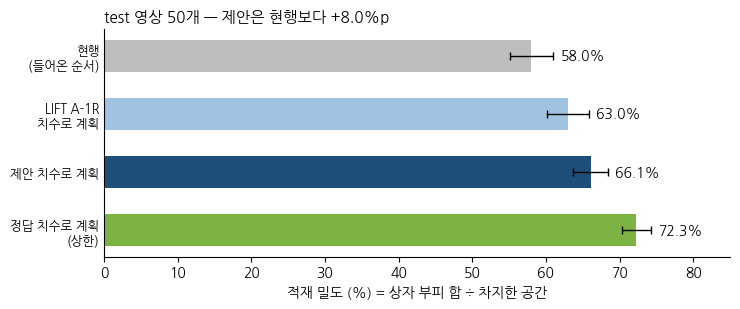

In [9]:
# [B-7] 그림 — test 적재 밀도, 핵심 4개 (막대 = 평균, 선 = 영상 단위 bootstrap 95% CI)
CORE = [(LOW, '현행\n(들어온 순서)', '#BDBDBD'),
        ('LIFT A-1R · 순서 계획', 'LIFT A-1R\n치수로 계획', '#9FC3E0'),
        (REF, '제안 치수로 계획', '#1F4E79'),
        ('상한 (정답 치수 · 큰 것부터)', '정답 치수로 계획\n(상한)', '#7CB342')]
m, lo_hi = [], []
for row, _, _ in CORE:
    x = pick(RES_T, row, BEST.get(row, '-'))['밀도 %']; m.append(x.mean()); lo_hi.append(boot_ci(x))
err = np.array([(v - lo, hi - v) for v, (lo, hi) in zip(m, lo_hi)]).T
ys = np.arange(len(CORE))[::-1]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(ys, m, 0.55, xerr=err, capsize=3, color=[c for *_, c in CORE], error_kw={'lw': 1, 'color': '#444'})
for y, v, (lo, hi), (row, _, _) in zip(ys, m, lo_hi, CORE):
    ax.text(hi + 1.0, y, f'{v:.1f}%', va='center', fontsize=10, fontweight='bold' if row == REF else 'normal')
ax.set_yticks(ys); ax.set_yticklabels([lab for _, lab, _ in CORE], fontsize=9)
ax.set_xlim(0, 85); ax.set_xlabel('적재 밀도 (%) = 상자 부피 합 ÷ 차지한 공간')
ax.spines[['top', 'right']].set_visible(False); ax.tick_params(axis='y', length=0)
d = (pick(RES_T, REF, BEST[REF])['밀도 %'] - pick(RES_T, LOW, BEST[LOW])['밀도 %']).dropna()
ax.set_title(f'test 영상 {RES_T.vid.nunique()}개 — 제안은 현행보다 {d.mean():+.1f}%p', fontsize=11, loc='left')
plt.tight_layout(); plt.savefig(f'{EXP_DIR}/binpack4_test_density.png', dpi=200); plt.show()


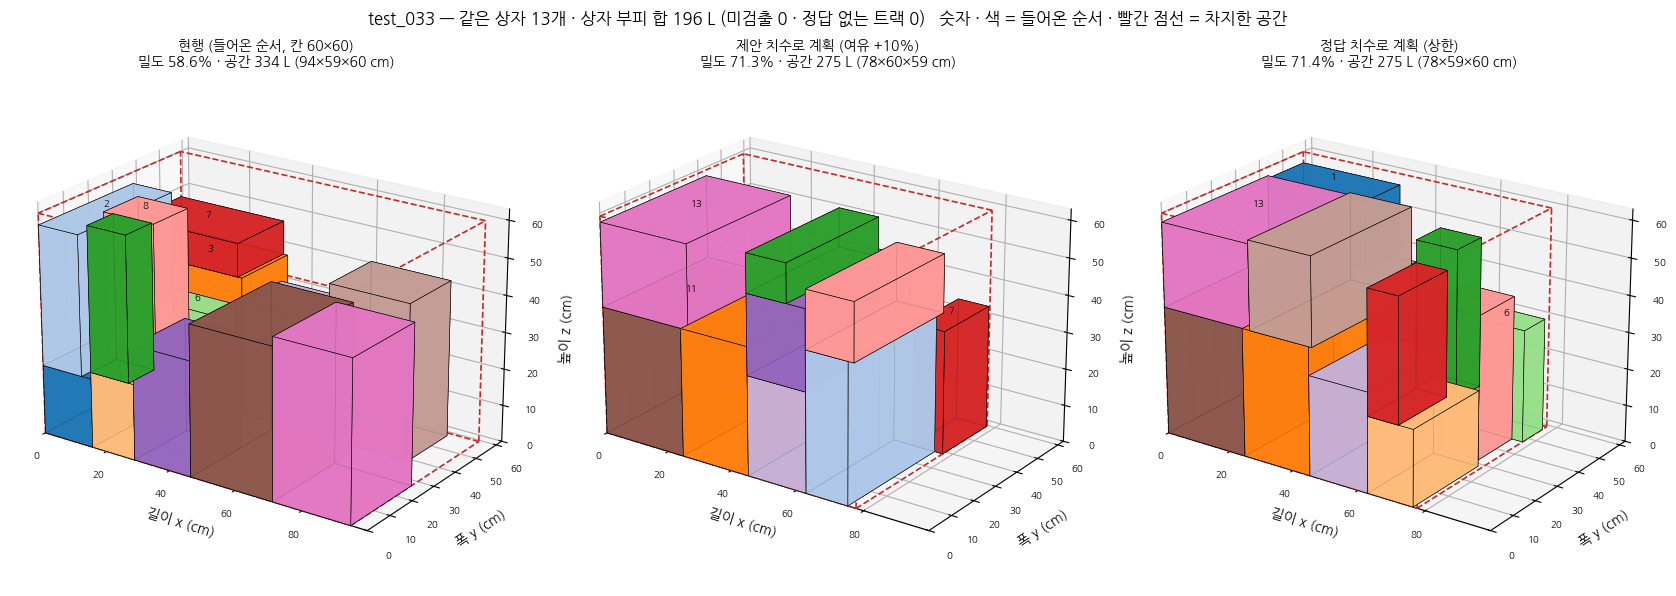

In [14]:
# [B-8] 적재 모습 — test 영상 하나: 현행 · 제안 · 상한을 3D로, 세 그림 모두 같은 축 범위 (공간 크기를 눈으로 비교)
#  상자 색 · 번호 = 들어온 순서 (세 그림과 [B-9] · [B-10]에서 같은 상자는 같은 색). 빨간 점선 = 차지한 공간 (밀도의 분모)
#  이 셀만 다시 돌려도 됨 (적재는 영상 하나만 새로 계산)
VIS_VID = 'test_005'  #@param {type:"string"}
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

if 'BEST' not in globals(): BEST = json.load(open(BEST_PATH))
PAL = [plt.get_cmap('tab20')(k) for k in range(20)]
color_of = lambda n: PAL[(n - 1) % 20]                                    # n = 들어온 순서 번호 (1부터)


def cuboid_faces(p, d):
    x, y, z = p; dx, dy, dz = d
    V = np.array([[x, y, z], [x + dx, y, z], [x + dx, y + dy, z], [x, y + dy, z], [x, y, z + dz], [x + dx, y, z + dz], [x + dx, y + dy, z + dz], [x, y + dy, z + dz]])
    return V, [[V[i] for i in f] for f in ([0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4], [2, 3, 7, 6], [1, 2, 6, 5], [0, 3, 7, 4])]


def draw(ax, ld, tags, title, lim):
    for (p, d), n in zip(zip(ld.lo, ld.sz), tags):
        _, F = cuboid_faces(p, d)
        ax.add_collection3d(Poly3DCollection(F, facecolor=color_of(n), edgecolor='k', linewidths=0.4, alpha=0.85))
        ax.text(p[0] + d[0] / 2, p[1] + d[1] / 2, p[2] + d[2], str(n), fontsize=7, ha='center', va='bottom', zorder=10)
    V, _ = cuboid_faces((0, 0, 0), ld.extent())                          # 차지한 공간 (빨간 점선)
    for a, b in ((0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)):
        ax.plot(*zip(V[a], V[b]), color='#C62828', lw=1.2, ls='--')
    ax.set_xlim(0, lim[0]); ax.set_ylim(0, lim[1]); ax.set_zlim(0, lim[2]); ax.set_box_aspect(lim); ax.view_init(elev=22, azim=-55)
    ax.set_xlabel('길이 x (cm)'); ax.set_ylabel('폭 y (cm)'); ax.set_zlabel('높이 z (cm)'); ax.tick_params(labelsize=7); ax.set_title(title, fontsize=10)


g = D4['test'][D4['test'].vid == VIS_VID].sort_values('first_frame', kind='stable')
assert len(g), f'{VIS_VID} 없음'
real = g[g.kind != 'fp']; seen = g[g.kind != 'missed']; miss = g[g.kind == 'missed']
NUM = {ix: n + 1 for n, ix in enumerate(real.index)}                    # 실제 상자 → 들어온 순서 번호
g_real = real[GT].values; vol = g_real.prod(1).sum(); is_fp = (seen.kind == 'fp').values; missed = miss[GT].values

_W, _H = map(int, BEST[LOW].replace('칸 ', '').split('×')); ord_low = list(range(len(g_real)))
L_low = pack(g_real, ord_low, _W, _H)[0]; T_low = [NUM[real.index[i]] for i in ord_low]
ord_up = list(np.argsort(-g_real.prod(1), kind='stable'))
L_up = pack_best(g_real, ord_up)[0]; T_up = [NUM[real.index[i]] for i in ord_up]
_, kind_, m_ = MARGIN_BY_NAME[BEST[REF]]
plan_ = sort3(inflate(seen[['prop_1', 'prop_2', 'prop_3']].values, kind_, m_))
L_prop, _, _ = plan_and_load(plan_, seen[GT].values, is_fp, missed, '순서 계획')
T_prop = [NUM[seen.index[i]] for i in np.argsort(-plan_.prod(1), kind='stable') if not is_fp[i]] + [NUM[ix] for ix in miss.index]
for ld, t in ((L_low, T_low), (L_up, T_up), (L_prop, T_prop)): assert len(ld.lo) == len(t)

PANELS = ((L_low, T_low, f'현행 (들어온 순서, {BEST[LOW]})'), (L_prop, T_prop, f'제안 치수로 계획 (여유 {BEST[REF]})'), (L_up, T_up, '정답 치수로 계획 (상한)'))
LIM = tuple(max(ld.extent()[k] for ld, _, _ in PANELS) * 1.05 for k in range(3))   # 세 그림 공통 축 범위
fig = plt.figure(figsize=(17, 5.8))
for j, (ld, t, nm) in enumerate(PANELS):
    draw(fig.add_subplot(1, 3, j + 1, projection='3d'), ld, t,
         f'{nm}\n밀도 {100 * vol / ld.volume():.1f}% · 공간 {ld.volume() / 1e3:.0f} L (' + '×'.join(f'{e:.0f}' for e in ld.extent()) + ' cm)', LIM)
plt.suptitle(f'{VIS_VID} — 같은 상자 {len(real)}개 · 상자 부피 합 {vol / 1e3:.0f} L (미검출 {len(missed)} · 정답 없는 트랙 {int(is_fp.sum())})'
             '   숫자 · 색 = 들어온 순서 · 빨간 점선 = 차지한 공간', y=1.02)
plt.tight_layout(); plt.savefig(f'{EXP_DIR}/binpack4_{VIS_VID}_3d.png', dpi=200, bbox_inches='tight'); plt.show()


In [15]:
# [B-9] 적재 모습 — 마우스로 돌려 보는 3D ([B-8]의 PANELS · LIM 그대로 사용, [B-8] 다음에 실행)
#  드래그 = 회전 · 휠 = 확대 · 상자에 마우스를 올리면 번호(들어온 순서) · 놓인 치수 표시. 색은 [B-8] · [B-10]과 같음. 같은 그림을 html로도 저장 (브라우저에서 열기)
import importlib.util, subprocess, sys
if importlib.util.find_spec('plotly') is None: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'plotly'], check=True)
import plotly.graph_objects as go
from plotly.subplots import make_subplots

TRI = dict(i=[0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1], j=[1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6], k=[2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5])
EDGES = ((0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7))


def edge_xyz(V):
    xs, ys, zs = [], [], []
    for a, b in EDGES:
        for v in (V[a], V[b]): xs.append(v[0]); ys.append(v[1]); zs.append(v[2])
        xs.append(None); ys.append(None); zs.append(None)
    return xs, ys, zs


rgb = lambda n: 'rgb' + str(tuple(int(255 * c) for c in color_of(n)[:3]))   # [B-8]과 같은 색
fig3 = make_subplots(rows=1, cols=3, specs=[[{'type': 'scene'}] * 3], horizontal_spacing=0.01,
                     subplot_titles=[f'{nm}<br>밀도 {100 * vol / ld.volume():.1f}% · 공간 {ld.volume() / 1e3:.0f} L' for ld, _, nm in PANELS])
for j, (ld, tags, nm) in enumerate(PANELS):
    ex, ey, ez = [], [], []
    for (p, d), n in zip(zip(ld.lo, ld.sz), tags):
        V, _ = cuboid_faces(p, d)
        fig3.add_trace(go.Mesh3d(x=V[:, 0], y=V[:, 1], z=V[:, 2], **TRI, color=rgb(n), opacity=1.0, flatshading=True,
                                 name=f'#{n}', hovertemplate=f'#{n} (들어온 순서)<br>' + ' × '.join(f'{v:.1f}' for v in d) + ' cm<extra></extra>'),
                       row=1, col=j + 1)
        a, b, c = edge_xyz(V); ex += a; ey += b; ez += c
    fig3.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode='lines', line=dict(color='black', width=2), hoverinfo='skip'), row=1, col=j + 1)
    a, b, c = edge_xyz(cuboid_faces((0, 0, 0), ld.extent())[0])       # 차지한 공간 (빨간 점선)
    fig3.add_trace(go.Scatter3d(x=a, y=b, z=c, mode='lines', line=dict(color='#C62828', width=4, dash='dash'), hoverinfo='skip'), row=1, col=j + 1)
r = max(LIM)
scene = dict(xaxis=dict(range=[0, LIM[0]], title='길이 x'), yaxis=dict(range=[0, LIM[1]], title='폭 y'), zaxis=dict(range=[0, LIM[2]], title='높이 z'),
             aspectmode='manual', aspectratio=dict(x=LIM[0] / r, y=LIM[1] / r, z=LIM[2] / r),
             camera=dict(eye=dict(x=1.05, y=-1.3, z=0.75)))
fig3.update_layout(**{f'scene{"" if j == 0 else j + 1}': scene for j in range(3)}, showlegend=False, height=560, width=1500,
                   margin=dict(l=0, r=0, t=110, b=0), title_y=0.97,
                   title=f'{VIS_VID} — 같은 상자 {len(real)}개 · 상자 부피 합 {vol / 1e3:.0f} L · 빨간 점선 = 차지한 공간')
fig3.write_html(f'{EXP_DIR}/binpack4_{VIS_VID}_3d.html', include_plotlyjs=True); fig3.show()
print('저장:', f'{EXP_DIR}/binpack4_{VIS_VID}_3d.html')


저장: /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/binpack/binpack4_test_033_3d.html


/tmp/ipykernel_2640/1938635488.py:31: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



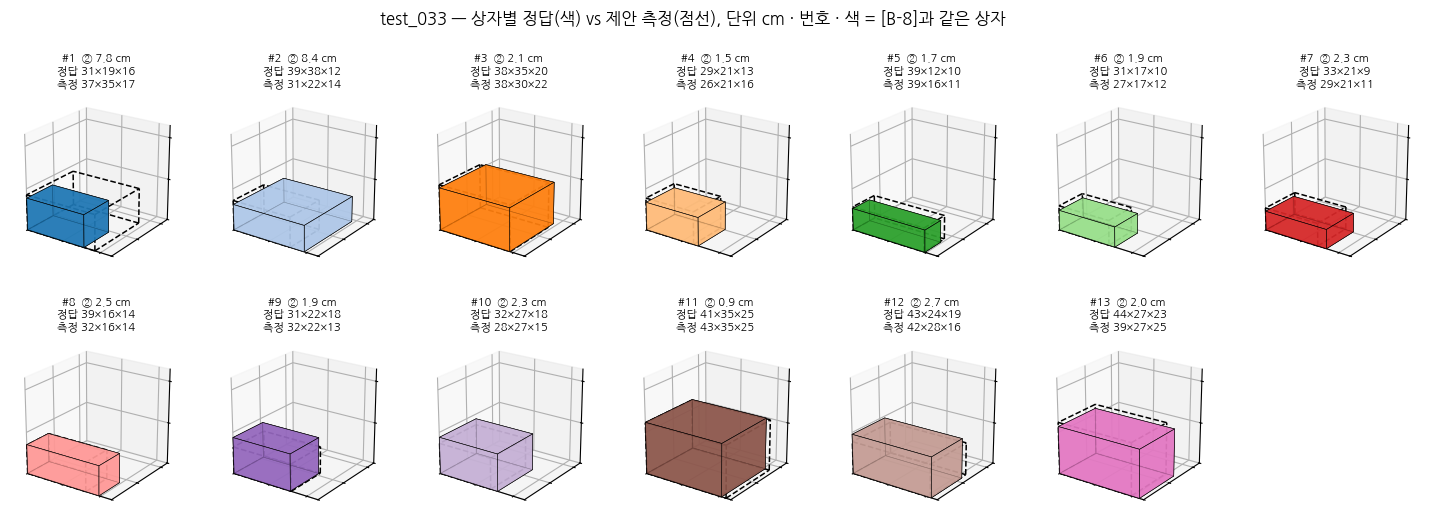

,번호,종류,box_id,tid,정답 (큰 순),측정 (큰 순),변별 오차 (측정 − 정답),② cm
0,1,매칭,1,0,31×19×16,37×35×17,+5.8 / +15.9 / +1.6,7.77
1,2,매칭,0,1,39×38×12,31×22×14,-7.4 / -15.8 / +1.9,8.38
2,3,매칭,2,2,38×35×20,38×30×22,+0.2 / -4.7 / +1.5,2.12
3,4,매칭,3,3,29×21×13,26×21×16,-2.5 / -0.0 / +2.0,1.51
4,5,매칭,4,4,39×12×10,39×16×11,-0.5 / +3.7 / +0.8,1.70
5,6,매칭,5,5,31×17×10,27×17×12,-3.2 / -0.4 / +2.2,1.93
6,7,매칭,6,6,33×21×9,29×21×11,-4.6 / +0.8 / +1.6,2.35
7,8,매칭,7,7,39×16×14,32×16×14,-6.9 / +0.3 / -0.2,2.50
8,9,매칭,8,8,31×22×18,32×22×13,+0.4 / +0.7 / -4.6,1.91
9,10,매칭,9,9,32×27×18,28×27×15,-3.7 / -0.2 / -2.9,2.28


매칭 상자 13개 · ② 평균 2.93 cm


In [16]:
# [B-10] 상자별 — 정답(색 채운 상자) vs 제안 측정(검은 점선), [B-8]과 같은 번호 · 색 ([B-8] 다음에 실행)
#  세 변을 큰 순으로 맞춰 같은 원점에 겹쳐 그림 (채점과 같은 정렬 매칭). 모든 칸이 같은 축 범위라 상자 크기끼리도 비교됨
#  측정 = 제안 (최종) 치수 그대로 (적재 여유를 더하기 전). 미검출 상자는 측정 없음, 정답 없는 트랙은 맨 뒤에 회색으로
items = [(NUM[ix], r) for ix, r in real.iterrows()] + [(None, r) for _, r in g[g.kind == 'fp'].iterrows()]
NC = 7; NR = int(np.ceil(len(items) / NC)); M = np.nanmax(np.r_[real[GT].values.ravel(), seen[['prop_1', 'prop_2', 'prop_3']].values.ravel()]) * 1.05
fig = plt.figure(figsize=(2.6 * NC, 2.9 * NR)); rows_ = []
for k, (n, r) in enumerate(items):
    ax = fig.add_subplot(NR, NC, k + 1, projection='3d')
    gt = r[GT].values.astype(float) if r.kind != 'fp' else None
    est = np.array([r.prop_1, r.prop_2, r.prop_3], float) if r.kind != 'missed' else None
    if gt is not None:
        _, F = cuboid_faces((0, 0, 0), gt)
        ax.add_collection3d(Poly3DCollection(F, facecolor=color_of(n), edgecolor='k', linewidths=0.4, alpha=0.75))
    if est is not None:
        V, _ = cuboid_faces((0, 0, 0), est)
        for a, b in ((0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)):
            ax.plot(*zip(V[a], V[b]), color='#9E9E9E' if gt is None else 'k', lw=1.1, ls='--')
    ax.set_xlim(0, M); ax.set_ylim(0, M); ax.set_zlim(0, M); ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=22, azim=-55)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    f = lambda v: '×'.join(f'{x:.0f}' for x in v)
    if gt is not None and est is not None:
        e2 = np.abs(est - gt).mean(); t = f'#{n}  ② {e2:.1f} cm\n정답 {f(gt)}\n측정 {f(est)}'
    elif gt is not None: e2 = np.nan; t = f'#{n}  미검출\n정답 {f(gt)}'
    else: e2 = np.nan; t = f'정답 없는 트랙\n측정 {f(est)}'
    ax.set_title(t, fontsize=8)
    rows_.append({'번호': n if n else '-', '종류': {'matched': '매칭', 'missed': '미검출', 'fp': '정답 없는 트랙'}[r.kind], 'box_id': r.get('box_id'), 'tid': r.tid,
                  '정답 (큰 순)': f(gt) if gt is not None else '-', '측정 (큰 순)': f(est) if est is not None else '-',
                  '변별 오차 (측정 − 정답)': ' / '.join(f'{x:+.1f}' for x in est - gt) if gt is not None and est is not None else '-',
                  '② cm': round(e2, 2) if e2 == e2 else '-'})
plt.suptitle(f'{VIS_VID} — 상자별 정답(색) vs 제안 측정(점선), 단위 cm · 번호 · 색 = [B-8]과 같은 상자', y=1.0)
plt.tight_layout(); plt.savefig(f'{EXP_DIR}/binpack4_{VIS_VID}_boxes.png', dpi=200, bbox_inches='tight'); plt.show()
BOX_TABLE = pd.DataFrame(rows_); display(BOX_TABLE)
e = pd.to_numeric(BOX_TABLE['② cm'], errors='coerce'); print(f'매칭 상자 {e.notna().sum()}개 · ② 평균 {e.mean():.2f} cm')
BOX_TABLE.to_csv(f'{EXP_DIR}/binpack4_{VIS_VID}_boxes.csv', index=False)


# **5. 보고 문장 (test 결과 반영)**
> 영상 하나를 하나의 적재 작업으로 보고, 검출을 놓친 상자와 정답 없는 트랙까지 포함해 실제 상자를 모두 실었을 때 차지한 공간으로 비교했다(높이 239 cm 이하, 받침 75%). val로 안전 여유와 현행의 표준 칸을 고른 뒤 test 50개 영상에 한 번 적용했다. 추정 치수로 적재 순서(큰 상자부터)와 칸을 계획하면 적재 밀도가 66.1%로, 들어온 순서대로 쌓는 현행(58.0%)보다 8.0%p(95% CI [5.2, 11.0]) 높았고, 같은 상자를 14% 작은 공간(173 vs 201 L)에 실었다. LIFT A-1R 치수로 계획한 경우보다는 3.1%p 높았다([0.3, 5.9], val에서는 같은 방향이나 유의하지 않음). 정답 치수로 계획한 상한(72.3%)과의 차이 6.2%p 중 검출 손실은 0.3%p뿐이고 대부분(5.9%p)이 치수 오차에서 왔다. 계획한 좌표에 그대로 놓는 엄격한 방식은 상자의 68%를 다시 놓아야 해서, 추정 치수는 정확한 좌표보다 적재 순서 · 구역 계획에 쓰는 것이 적합하다.

### 한계
- 적재 규칙은 탐욕(greedy) 휴리스틱이라 상한도 최적해는 아니다 (모든 행에 같은 규칙)
- 미검출 상자의 도착 순서는 box_id 순서로 추정했다
- 순서 바꾸기는 영상(배치) 안의 상자를 모두 잰 뒤 싣는다고 가정한다 (적재 전 임시 보관 공간)
